# Static MB calibration against WGMS data with the AdaPBS

OGGM's `mb_calibration_to_rmsd` finds the mass balance (MB) parameters
(`melt_f`, `prcp_fac`, `temp_bias`) which minimise the RMSD between the modelled
and the observed (WGMS) annual MB of a glacier. It returns one parameter set.

Here we do the Bayesian version of this with the adaptive particle batch smoother
(AdaPBS): given a prior distribution of the parameters and observations with
errors, it returns weighted samples of the **posterior** distribution. This tells
us not only the best parameters, but also how well the observations constrain
them, and which combinations of parameters are equally good (equifinality).

The geometry is fixed (the inversion flowlines), as in `mb_calibration_to_rmsd`:
one model run is a few milliseconds, so we can afford thousands of them.

We compare five sets of observations:

| experiment | observations |
|---|---|
| `mean` | the mean annual MB over the period (one number, like a geodetic MB) |
| `annual` | the annual MB time series (the AdaPBS equivalent of `mb_calibration_to_rmsd`) |
| `winter` | the winter MB time series |
| `summer` | the summer MB time series |
| `winter+summer` | both seasonal series together |

The AdaPBS is the work of K. Aalstad and E. Alonso-González (MuSA). If you use it,
please cite Aalstad et al. (2026, https://doi.org/10.5194/gmd-19-8565-2026) and
Alonso-González et al. (2022, https://doi.org/10.5194/gmd-15-9127-2022).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from oggm import cfg, utils, workflow
from oggm.core.massbalance import mb_calibration_to_rmsd

from oggm_adapbs import run_adapbs, glogit, gexpit, weighted_quantile, weighted_summary
from oggm_adapbs.massbalance import mb_prior, static_mb_model, seasonal_specific_mb

## Glacier and data

We use Vernagtferner (Ötztal Alps, Austria), which has 40 years of winter and
summer MB in OGGM's WGMS data over the period of the W5E5 climate data
(1979-2019). Its neighbour Hintereisferner (`RGI60-11.00897`) works too, but has
seasonal data since 2013 only.

We start from the OGGM preprocessed directories at level 3 (W5E5 climate,
elevation band flowlines).

In [2]:
cfg.initialize(logging_level='WARNING')
cfg.PATHS['working_dir'] = utils.gettempdir('adapbs_wgms_calibration', reset=True)

rgi_id = 'RGI60-11.00719'  # Vernagtferner
base_url = ('https://cluster.klima.uni-bremen.de/~oggm/gdirs/oggm_v1.6/'
            'L3-L5_files/2025.6/elev_bands/W5E5/per_glacier/')
gdir = workflow.init_glacier_directories([rgi_id], from_prepro_level=3,
                                         prepro_border=80,
                                         prepro_base_url=base_url)[0]

# The temperature bias file used by OGGM to inform the temp_bias prior
temp_bias_file = ('https://cluster.klima.uni-bremen.de/~oggm/ref_mb_params/oggm_v1.6/'
                  'w5e5_rgi6_perglacier_temp_bias_v2025.6.2.csv')
gdir.name

2026-11-11 14:33:30: oggm.cfg: Reading default parameters from the OGGM `params.cfg` configuration file.


2026-11-11 14:33:30: oggm.cfg: Multiprocessing switched OFF according to the parameter file.


2026-11-11 14:33:30: oggm.cfg: Multiprocessing: using all available processors (N=10)


2026-11-11 14:33:31: oggm.workflow: init_glacier_directories from prepro level 3 on 1 glaciers.


2026-11-11 14:33:31: oggm.workflow: Execute entity tasks [gdir_from_prepro] on 1 glaciers


'Vernagtferner'

The WGMS MB is given for hydrological years (October to September), with a
winter (October to April) and a summer (May to September) balance. We keep the
years with all three values. The climate data end in 2019.

In [3]:
ref = gdir.get_ref_mb_data(y0=1980, y1=2019)
ref = ref[['WINTER_BALANCE', 'SUMMER_BALANCE', 'ANNUAL_BALANCE']].dropna()
ref.columns = ['winter', 'summer', 'annual']
years = ref.index.values
print(f'{len(years)} years: {years[0]}-{years[-1]}')
ref.describe().round(0)

39 years: 1980-2019


,winter,summer,annual
count,39.0,39.0,39.0
mean,916.0,-1587.0,-670.0
std,195.0,473.0,458.0
min,486.0,-3119.0,-2133.0
25%,862.0,-1906.0,-957.0
50%,912.0,-1457.0,-568.0
75%,1022.0,-1288.0,-355.0
max,1410.0,-728.0,140.0


## Deterministic reference: `mb_calibration_to_rmsd`

The three parameters together, with OGGM's default bounds (wide). Note that
`mb_calibration_to_rmsd` compares the WGMS data (hydrological years) to the
model's calendar years, while we use hydrological years for the AdaPBS below.

In [4]:
det = mb_calibration_to_rmsd(gdir, ref_df=ref['annual'],
                             calibrate_params=('melt_f', 'prcp_fac', 'temp_bias'),
                             write_to_gdir=False, optimisation_kwargs={'seed': 0})
params = ['melt_f', 'prcp_fac', 'temp_bias']
print({p: round(det[p], 2) for p in params}, f"RMSD: {det['rmsd']:.0f} kg m-2")

/Users/uu23343/Library/CloudStorage/Dropbox/HomeDocs/git/oggm-mac/oggm/utils/_workflow.py:125: UserWarning: Store data not found, attempting to read pickle file instead.
  warnings.warn(


{'melt_f': np.float64(3.38), 'prcp_fac': np.float64(1.19), 'temp_bias': np.float64(1.72)} RMSD: 250 kg m-2


## Prior

Each parameter has a logit-normal prior: Gaussian (here with a standard
deviation of 1) in a transformed "normal space", and bounded in the parameter
space. `mb_prior` centres it on OGGM's informed guesses:

- `melt_f`: 5 (`cfg.PARAMS['melt_f']`), bounds 1.5 to 17
- `prcp_fac`: from the winter precipitation (as in OGGM's informed three-step
  calibration), bounds half and twice that
- `temp_bias`: from the temperature bias file, bounds +- 3 K

Note that the deterministic `prcp_fac` above is outside these bounds.

In [5]:
prior = mb_prior(gdir, params, temp_bias_file_path=temp_bias_file)
x_min, x_max = prior['x_min'], prior['x_max']
prior_mean = glogit(prior['x_centre'], x_min, x_max)

# Samples of the prior, to see what it looks like
rng = np.random.default_rng(0)
prior_theta = gexpit(prior_mean + rng.standard_normal((10000, 3)), x_min, x_max)
prior_df = weighted_summary(prior_theta, np.ones(10000) / 10000, params)
prior_df['centre'], prior_df['min'], prior_df['max'] = prior['x_centre'], x_min, x_max
prior_df.round(2)

,q5,q50,q95,mean,centre,min,max
melt_f,2.36,5.01,10.84,5.60,5.00,1.50,17.00
prcp_fac,2.14,3.35,5.28,3.49,3.36,1.68,6.71
temp_bias,-0.34,1.70,3.73,1.71,1.71,-1.29,4.71


## Observation errors

The likelihood assumes independent Gaussian errors. The error must include the
measurement error *and* the model error (the MB model with gridded climate data
cannot reproduce every year): the latter dominates. We use the misfit of the
deterministic calibration as a measure of it:

- annual MB: the RMSD of the deterministic calibration ($\sigma_a$). With this
  choice, the `annual` experiment is the probabilistic counterpart of
  `mb_calibration_to_rmsd`: its most likely parameters minimise the RMSD.
- winter and summer MB: $\sigma_a / \sqrt{2}$ each, so that the two seasons
  together carry the same error as the annual MB.
- mean MB: $\sigma_a / \sqrt{N}$ (N years), the same information on the mean as
  the annual series, but no information on the year-to-year variability.

These are choices: the width of the posterior scales with them. Also, the model
errors of consecutive years are not independent in reality, which makes these
posteriors too narrow.

In [6]:
n = len(years)
sigma_a = det['rmsd']
sigma = {'annual': sigma_a, 'winter': sigma_a / np.sqrt(2), 'summer': sigma_a / np.sqrt(2)}
print({k: round(v) for k, v in sigma.items()}, f'mean: {sigma_a / np.sqrt(n):.0f}')

def observe(df, target):
    # The observed quantities of an experiment, from a DataFrame of
    # winter, summer, annual MB
    if target == 'mean':
        return np.array([df['annual'].mean()])
    return np.concatenate([df[k].values for k in target.split('+')])

def obs_errors(target):
    if target == 'mean':
        return np.array([sigma_a / np.sqrt(n)])
    return np.concatenate([np.repeat(sigma[k], n) for k in target.split('+')])

{'annual': 250, 'winter': 177, 'summer': 177} mean: 40


## Forward model

The AdaPBS calls `forward(theta, iteration)` with a batch of parameter sets
(one row per particle) and expects the predicted observations (one row per
particle). We also return the full seasonal series of each particle as
"extras", to look at the fit afterwards.

In [7]:
mb_mod, fls = static_mb_model(gdir, prior['centre'])
seasons = ['winter', 'summer', 'annual']

def make_forward(target):
    def forward(theta, iteration):
        pred, extras = [], {k: [] for k in seasons}
        for th in theta:
            for p, v in zip(params, th):
                setattr(mb_mod, p, v)
            df = seasonal_specific_mb(mb_mod, fls, years)
            for k in seasons:
                extras[k].append(df[k].values)
            pred.append(observe(df, target))
        return np.array(pred), {k: np.array(v) for k, v in extras.items()}
    return forward

## Run the AdaPBS

300 particles per iteration, at most 10 iterations. The AdaPBS stops when the
effective sample size (Neff) of the weighted particles is above 30% of the
particles per iteration.

In [8]:
experiments = ['mean', 'annual', 'winter', 'summer', 'winter+summer']
results = {}
for target in experiments:
    results[target] = run_adapbs(make_forward(target), observe(ref, target),
                                 obs_errors(target), x_min, x_max,
                                 prior_mean=prior_mean, prior_sd=1.,
                                 n_particles=300, max_iterations=10,
                                 neff_threshold=0.3, rng=np.random.default_rng(0))

pd.DataFrame({t: {'iterations': len(r['diagnostics']),
                  'model runs': len(r['weights']),
                  'final Neff': r['diagnostics']['neff'].iloc[-1]}
              for t, r in results.items()}).T.round(0)

,iterations,model runs,final Neff
mean,3.0,900.0,101.0
annual,6.0,1800.0,110.0
winter,3.0,900.0,286.0
summer,7.0,2100.0,184.0
winter+summer,5.0,1500.0,223.0


## Posterior

Posterior median and 5-95% range of each parameter, next to the prior and the
deterministic calibration.

In [9]:
def fmt(row):
    return f"{row['q50']:.2f} [{row['q5']:.2f}, {row['q95']:.2f}]"

table = {'prior': prior_df.apply(fmt, axis=1)}
for t, r in results.items():
    table[t] = weighted_summary(r['theta'], r['weights'], params).apply(fmt, axis=1)
table = pd.DataFrame(table).T
table.loc['mb_calibration_to_rmsd'] = [f'{det[p]:.2f}' for p in params]
table

,melt_f,prcp_fac,temp_bias
prior,"5.01 [2.36, 10.84]","3.35 [2.14, 5.28]","1.70 [-0.34, 3.73]"
mean,"4.52 [3.01, 9.50]","2.95 [1.97, 4.09]","2.36 [0.52, 3.55]"
annual,"3.32 [2.85, 4.02]","1.96 [1.87, 2.24]","2.49 [1.93, 3.09]"
winter,"3.97 [2.21, 9.98]","2.56 [2.42, 2.68]","0.33 [-0.80, 1.78]"
summer,"3.48 [2.99, 4.13]","1.94 [1.82, 2.22]","2.88 [2.32, 3.37]"
winter+summer,"3.70 [3.22, 4.11]","2.59 [2.44, 2.74]","2.79 [2.42, 3.22]"
mb_calibration_to_rmsd,3.38,1.19,1.72


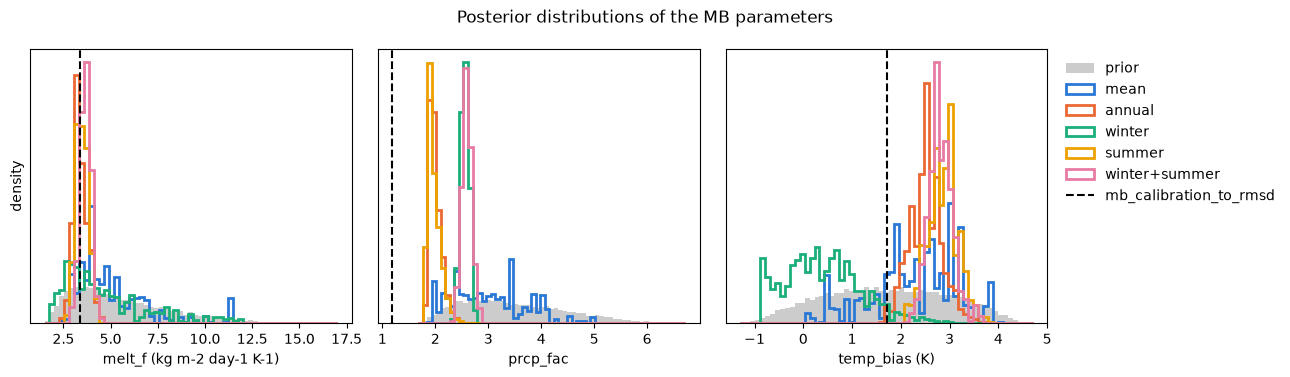

In [10]:
colors = {'mean': '#2a78d6', 'annual': '#eb6834', 'winter': '#1baf7a',
          'summer': '#eda100', 'winter+summer': '#e87ba4'}
labels = {'melt_f': 'melt_f (kg m-2 day-1 K-1)', 'prcp_fac': 'prcp_fac',
          'temp_bias': 'temp_bias (K)'}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for k, (ax, p) in enumerate(zip(axes, params)):
    bins = np.linspace(x_min[k], x_max[k], 60)
    ax.hist(prior_theta[:, k], bins=bins, density=True, color='0.8', label='prior')
    for t, r in results.items():
        ax.hist(r['theta'][:, k], bins=bins, weights=r['weights'], density=True,
                histtype='step', lw=2, color=colors[t], label=t)
    ax.axvline(det[p], color='k', ls='--', lw=1.5, label='mb_calibration_to_rmsd')
    ax.set_xlabel(labels[p])
    ax.set_yticks([])
axes[0].set_ylabel('density')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
fig.suptitle('Posterior distributions of the MB parameters')
plt.tight_layout()

The posteriors are much more informative together: pairs of parameters,
plotted with the resampled (equally weighted) posterior particles.

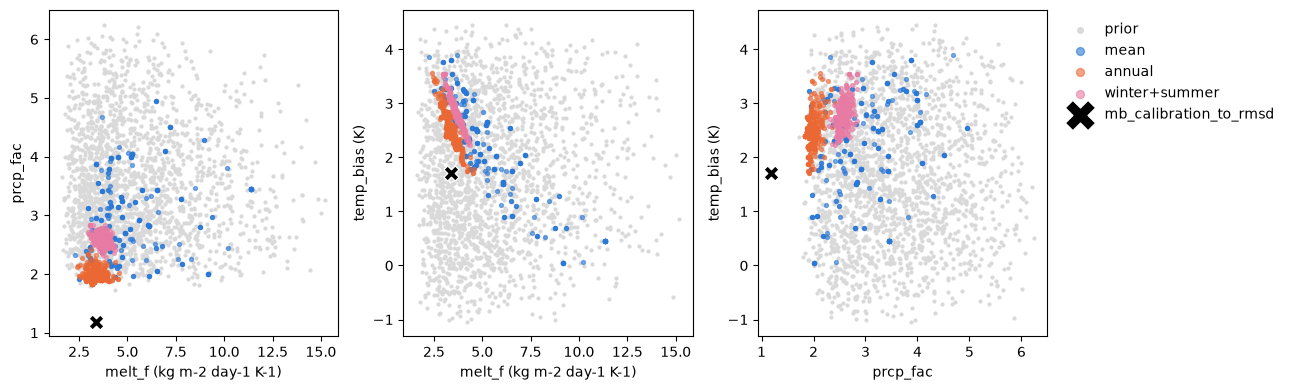

In [11]:
pairs = [('melt_f', 'prcp_fac'), ('melt_f', 'temp_bias'), ('prcp_fac', 'temp_bias')]
show = ['mean', 'annual', 'winter+summer']

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (px, py) in zip(axes, pairs):
    ix, iy = params.index(px), params.index(py)
    ax.scatter(prior_theta[:2000, ix], prior_theta[:2000, iy], s=4, color='0.85',
               label='prior')
    for t in show:
        post = results[t]['posterior_theta']
        ax.scatter(post[:, ix], post[:, iy], s=8, color=colors[t], alpha=0.6,
                   label=t)
    ax.scatter(det[px], det[py], marker='X', s=120, color='k',
               edgecolor='w', label='mb_calibration_to_rmsd', zorder=5)
    ax.set_xlabel(labels[px])
    ax.set_ylabel(labels[py])
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False,
                markerscale=2)
plt.tight_layout()

## Fit to the observations

The posterior predictive distribution (5-95% range of the modelled MB over the
weighted particles) of two experiments, against the WGMS data.

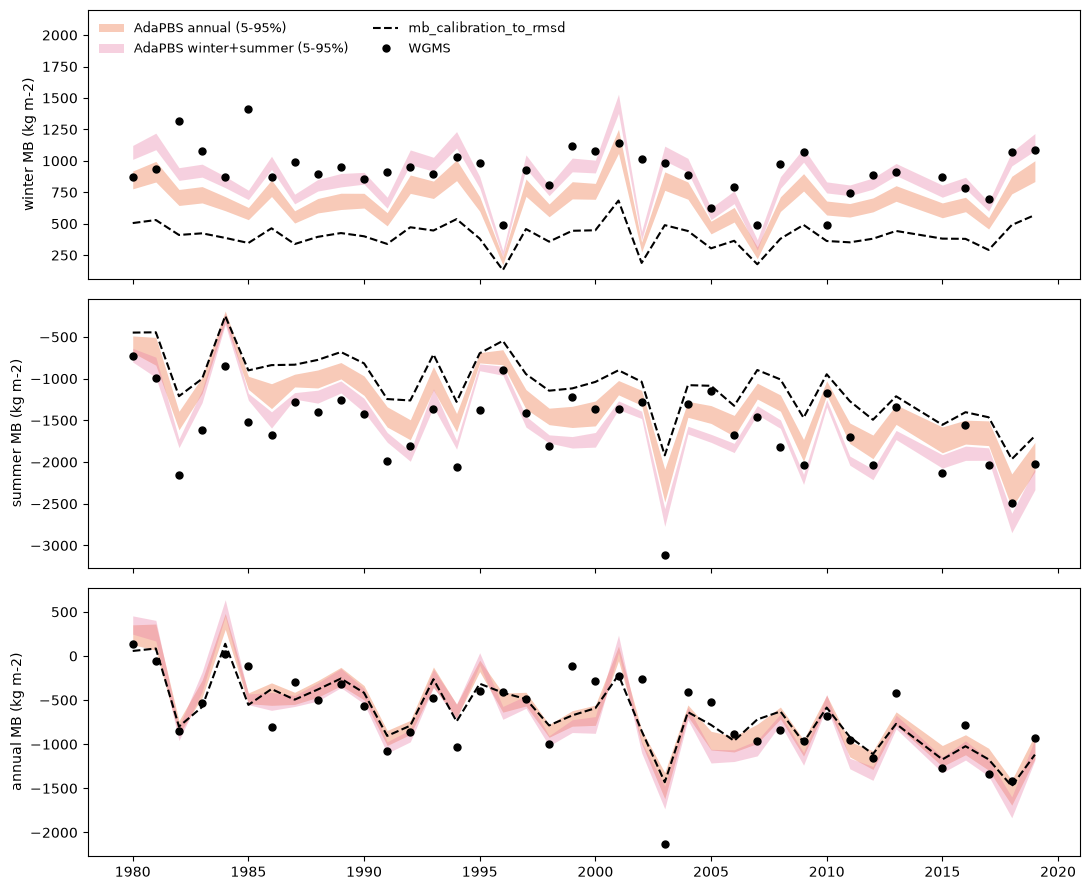

In [12]:
def band(r, season, q):
    x = r['extras'][season]
    return np.array([weighted_quantile(x[:, i], r['weights'], q)
                     for i in range(x.shape[1])])

for p in params:
    setattr(mb_mod, p, det[p])
det_mb = seasonal_specific_mb(mb_mod, fls, years)

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, s in zip(axes, seasons):
    for t in ['annual', 'winter+summer']:
        r = results[t]
        ax.fill_between(years, band(r, s, 0.05), band(r, s, 0.95),
                        color=colors[t], alpha=0.35, lw=0, label=f'AdaPBS {t} (5-95%)')
    ax.plot(years, det_mb[s], color='k', ls='--', lw=1.5, label='mb_calibration_to_rmsd')
    ax.plot(years, ref[s], 'o', color='k', ms=5, label='WGMS')
    ax.set_ylabel(f'{s} MB (kg m-2)')
axes[0].legend(ncol=2, loc='upper left', frameon=False, fontsize=9)
axes[0].set_ylim(top=axes[0].get_ylim()[1] + 600)
plt.tight_layout()

In [13]:
# RMSD and mean bias of the posterior mean MB, per season
rows = {}
for t in ['annual', 'winter+summer']:
    r = results[t]
    for s in seasons:
        m = np.average(r['extras'][s], axis=0, weights=r['weights'])
        rows[(t, s)] = {'RMSD': np.sqrt(np.mean((m - ref[s]) ** 2)),
                        'bias': np.mean(m - ref[s])}
for s in seasons:
    rows[('mb_calibration_to_rmsd', s)] = {'RMSD': np.sqrt(np.mean((det_mb[s] - ref[s]) ** 2)),
                                           'bias': np.mean(det_mb[s] - ref[s])}
pd.DataFrame(rows).T.unstack().round(0)

RMSD                 bias              
                       annual summer winter annual summer winter
annual                  275.0  361.0  306.0   10.0  261.0 -250.0
mb_calibration_to_rmsd  251.0  565.0  536.0    2.0  513.0 -511.0
winter+summer           316.0  278.0  211.0  -39.0   20.0  -60.0

## Take-aways

- **`mean`**: one number constrains one combination of parameters. The
  posterior stays close to the prior, apart from a ridge where `melt_f` and
  `temp_bias` trade off (equifinality). This is the situation of the calibration
  to geodetic MB.
- **`annual`** (the AdaPBS equivalent of `mb_calibration_to_rmsd`): the
  year-to-year variability adds information, and the posterior is narrow. It
  agrees with the deterministic `melt_f` (~3.3), but the deterministic
  `prcp_fac` (1.19) is far below the prior range: within the prior, the annual
  data push `prcp_fac` to the low end (~2) and `temp_bias` up.
- **`winter`** constrains `prcp_fac` (2.56 [2.42, 2.68]) but not `melt_f`.
  **`summer`** constrains `melt_f` and `temp_bias`, and also prefers a low
  `prcp_fac` (summer snowfall is part of the summer balance).
- **`winter+summer`** constrains all three parameters, and the model fits the
  winter and summer MB without bias. The calibrations to the annual MB fit the
  annual MB slightly better, but with a too small seasonal amplitude: low
  accumulation and low melt (seasonal biases of +-250 kg m-2 for the AdaPBS,
  +-510 kg m-2 for `mb_calibration_to_rmsd`). The annual MB alone cannot tell
  these solutions apart.
- Cost: 900 to 2100 model runs per experiment, a few seconds to half a minute
  on a laptop.

## Caveats

- The observation errors are a choice (see above), and the years are treated
  as independent: the posteriors are probably too narrow.
- The prior bounds matter where the posterior reaches them.
- WGMS seasonal balances are measured either at fixed dates or with the
  stratigraphic method: the model's October-April / May-September split is an
  approximation.
- The geometry is fixed: this calibrates the MB model, not the glacier evolution.